# Latihan Responsi Praktikum Data Science - Klasifikasi

## Lembar Jawab
Isi identitas Anda pada sel di bawah **sebelum mengerjakan**. Sel akan menampilkan error jika ada yang masih kosong. Setelah selesai, simpan notebook ini dengan nama `[NIM]_Latihan_Klasifikasi_IF-[kelas].ipynb` (ganti `[NIM]` dan `[kelas]`).

In [1]:
# ===== LEMBAR JAWAB =====
nama  = "Reno Miftahudin"    
nim   = "123240248"    
kelas = "IF_I"   

assert nama.strip() and nim.strip() and kelas.strip(), "Isi nama, nim, dan kelas terlebih dahulu!"
print(f"Nama : {nama}\nNIM  : {nim}\nKelas: {kelas}")

Nama : Reno Miftahudin
NIM  : 123240248
Kelas: IF_I


## Ketentuan Latihan Responsi
- **Materi:** sama dengan latihan responsi (Data Insight -> Preprocessing & Split -> Feature Selection & EDA -> Supervised Modelling -> Evaluation -> Feature Importance).
- **Alokasi waktu:** 120 menit.
- **Sifat:** *open note*; diperbolehkan membawa print-an berapa pun.
- Menggunakan PC laboratorium; jika ada kendala boleh memakai laptop pribadi dengan pengawasan.
- Tas dikumpulkan sebelum pelaksanaan kuis.
- Kerjakan langsung di notebook ini pada sel yang disediakan. Pastikan seluruh sel dapat dijalankan berurutan (*Restart & Run All*) tanpa error.
- Gunakan `random_state=42` di semua proses yang melibatkan keacakan.
- Pelanggaran *data leakage* (mis. `fit` scaler atau menghitung median dari data test / seluruh data) mengurangi poin pada soal terkait.

## Dataset
**Palmer Penguins** (`penguins_latihan.csv`): pengukuran tiga spesies penguin di Kepulauan Palmer, Antartika.

| Kolom | Keterangan |
|---|---|
| **species** | **Target klasifikasi** (Adelie / Chinstrap / Gentoo) |
| island, sex | Pulau asal dan jenis kelamin (tidak dipakai pada soal ini) |
| bill_length_mm, bill_depth_mm | Panjang & kedalaman paruh (mm) |
| flipper_length_mm | Panjang sirip (mm) |
| body_mass_g | Massa tubuh (gram) |

> Dataset ini sengaja memuat data kotor (missing value, duplikat, nilai mustahil).

**Tugas:** klasifikasi - target `species`.

## Komposisi Penilaian
| Fase | Soal | Bobot |
|---|---|---|
| **Fase 1 - Data Insight** | | **10** |
| | 1.1 | 5 |
| | 1.2 | 5 |
| **Fase 2 - Data Preprocessing & Split** | | **15** |
| | 2.1 | 5 |
| | 2.2 | 4 |
| | 2.3 | 6 |
| **Fase 3 - Feature Selection & EDA** | | **15** |
| | 3.1 | 6 |
| | 3.2 | 4 |
| | 3.3 | 5 |
| **Fase 4 - Supervised Modelling (Klasifikasi: SVM vs Random Forest)** | | **25** |
| | 4.1 | 10 |
| | 4.2 | 10 |
| | 4.3 | 5 |
| **Fase 5 - Evaluation & Contrast** | | **25** |
| | 5.1 | 14 |
| | 5.2 | 11 |
| **Fase 6 - Feature Importance** | | **10** |
| | 6.1 | 7 |
| | 6.2 | 3 |
| **TOTAL** | | **100** |

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

import warnings
warnings.filterwarnings("ignore")

## Fase 1 - Data Insight (10 poin)

**Soal 1.1** (5 poin)

Baca `penguins_latihan.csv` dengan Pandas ke DataFrame `df`. Tampilkan 5 baris pertama, `df.info()`, jumlah *missing value* per kolom, dan jumlah baris duplikat.

In [3]:

# Membaca dataset
df = pd.read_csv('penguins_latihan.csv')

# Menampilkan 5 baris pertama
print("5 Baris Pertama:")
display(df.head())

# Informasi dataset
print("\nInformasi Dataset:")
df.info()

# Jumlah missing value setiap kolom
print("\nJumlah Missing Value:")
print(df.isnull().sum())

# Jumlah baris duplikat
print("\nJumlah Baris Duplikat:")
print(df.duplicated().sum())


5 Baris Pertama:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Chinstrap,Dream,52.2,18.8,197.0,3450.0,MALE
1,Gentoo,Biscoe,55.1,16.0,230.0,5850.0,MALE
2,Adelie,Biscoe,42.7,18.3,196.0,4075.0,MALE
3,Adelie,Torgersen,34.6,21.1,198.0,4400.0,MALE
4,Gentoo,Biscoe,40.9,13.7,214.0,4650.0,FEMALE



Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 347 entries, 0 to 346
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            347 non-null    str    
 1   island             347 non-null    str    
 2   bill_length_mm     345 non-null    float64
 3   bill_depth_mm      345 non-null    float64
 4   flipper_length_mm  345 non-null    float64
 5   body_mass_g        345 non-null    float64
 6   sex                336 non-null    str    
dtypes: float64(4), str(3)
memory usage: 25.1 KB

Jumlah Missing Value:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Jumlah Baris Duplikat:
3


**Soal 1.2** (5 poin)

Tampilkan `df.describe()` dan jumlah data per kelas `species`. Pada Markdown tulis: (a) jumlah baris dan kolom, (b) **dua masalah kualitas data** yang Anda temukan (petunjuk: perhatikan nilai min/max pada `describe()`).

In [4]:

# Statistik deskriptif
print("Statistik Deskriptif:")
display(df.describe())

# Jumlah data setiap kelas
print("\nJumlah Data per Kelas:")
print(df['species'].value_counts())


Statistik Deskriptif:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,345.000000,345.000000,345.000000,345.000000
mean,43.918841,17.154203,199.652174,4196.304348
std,5.446945,1.967377,20.703490,801.274717
min,32.100000,13.100000,0.000000,2700.000000
25%,39.300000,15.600000,190.000000,3550.000000
50%,44.400000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000



Jumlah Data per Kelas:
species
Adelie       154
Gentoo       124
Chinstrap     69
Name: count, dtype: int64


**Jawaban 1.2:**

Berdasarkan hasil analisis dataset Palmer Penguins, diperoleh jumlah data sebanyak **347 baris dan 7 kolom**.

Ditemukan beberapa permasalahan kualitas data, yaitu:

1. Terdapat missing value pada beberapa kolom numerik, yaitu `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, dan `body_mass_g`, masing-masing sebanyak 2 data. Kolom `sex` memiliki 11 missing value.
2. Terdapat nilai yang tidak valid pada kolom `flipper_length_mm`, yaitu nilai minimum 0 mm. Nilai tersebut tidak mungkin karena panjang sirip penguin tidak mungkin bernilai nol.

Selain itu, ditemukan 3 baris duplikat yang perlu ditangani pada tahap preprocessing.

Distribusi kelas terdiri dari Adelie sebanyak 154 data, Gentoo sebanyak 124 data, dan Chinstrap sebanyak 69 data.

## Fase 2 - Data Preprocessing & Split (15 poin)
> **Anti-data leakage:** statistik apa pun (median, mean, dsb.) hanya boleh dihitung dari **train** lalu diterapkan ke test (lihat Modul 6, Dasar Teori 3.2).

**Soal 2.1** (5 poin)

Lakukan *data cleaning* **tanpa statistik data** (belum boleh imputasi). Simpan hasilnya di `df_clean` dan cetak ukuran sebelum & sesudah:
  a. Hapus baris duplikat.
  b. Hapus kolom `island` dan `sex` (soal ini hanya memakai fitur numerik).
  c. Kolom `flipper_length_mm` memuat nilai mustahil (panjang sirip tidak mungkin 0; periksa `describe()`): ubah nilai tersebut menjadi `NaN`.
  d. Hapus baris yang `species`-nya kosong.

In [5]:

# Menampilkan ukuran data sebelum cleaning
print("Ukuran Data Sebelum Cleaning:", df.shape)

# Menghapus data duplikat
df_clean = df.drop_duplicates().copy()

# Menghapus kolom island dan sex
df_clean = df_clean.drop(columns=['island', 'sex'])

# Mengubah nilai 0 pada flipper_length_mm menjadi NaN
df_clean.loc[
    df_clean['flipper_length_mm'] == 0,
    'flipper_length_mm'
] = np.nan

# Menghapus baris dengan species kosong
df_clean = df_clean.dropna(subset=['species'])

# Menampilkan ukuran data setelah cleaning
print("Ukuran Data Setelah Cleaning:", df_clean.shape)

# Menampilkan hasil cleaning
display(df_clean.head())


Ukuran Data Sebelum Cleaning: (347, 7)
Ukuran Data Setelah Cleaning: (344, 5)


,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,Chinstrap,52.2,18.8,197.0,3450.0
1,Gentoo,55.1,16.0,230.0,5850.0
2,Adelie,42.7,18.3,196.0,4075.0
3,Adelie,34.6,21.1,198.0,4400.0
4,Gentoo,40.9,13.7,214.0,4650.0


**Soal 2.2** (4 poin)

Bagi `df_clean` menjadi `train_df` dan `test_df` dengan rasio **80:20**, `random_state=42`, dan `stratify` berdasarkan `species`. Gunakan `.copy()` pada keduanya.

In [6]:

# Membagi data menjadi train dan test
train_df, test_df = train_test_split(
    df_clean,
    test_size=0.2,
    random_state=42,
    stratify=df_clean['species']
)

# Menggunakan copy()
train_df = train_df.copy()
test_df = test_df.copy()

# Menampilkan ukuran data
print("Ukuran Train Data:", train_df.shape)
print("Ukuran Test Data:", test_df.shape)

# Distribusi kelas pada train dan test
print("\nDistribusi Kelas Train:")
print(train_df['species'].value_counts())

print("\nDistribusi Kelas Test:")
print(test_df['species'].value_counts())


Ukuran Train Data: (275, 5)
Ukuran Test Data: (69, 5)

Distribusi Kelas Train:
species
Adelie       122
Gentoo        99
Chinstrap     54
Name: count, dtype: int64

Distribusi Kelas Test:
species
Adelie       30
Gentoo       25
Chinstrap    14
Name: count, dtype: int64


**Soal 2.3** (6 poin)

Isi *missing value* pada kolom numerik (seluruh kolom fitur) dengan **median train**; terapkan nilai median yang sama ke `train_df` **dan** `test_df`. Buktikan tidak ada missing value tersisa dan tampilkan ukuran kedua set.

In [7]:

# Menghitung median hanya dari data train
median_train = train_df.select_dtypes(
    include=np.number
).median()

print("Median Data Train:")
print(median_train)

# Mengisi missing value pada train dan test
train_df[median_train.index] = train_df[
    median_train.index
].fillna(median_train)

test_df[median_train.index] = test_df[
    median_train.index
].fillna(median_train)

# Memeriksa missing value setelah imputasi
print("\nMissing Value Train:")
print(train_df.isnull().sum())

print("\nMissing Value Test:")
print(test_df.isnull().sum())

# Menampilkan ukuran data
print("\nUkuran Train:", train_df.shape)
print("Ukuran Test:", test_df.shape)


Median Data Train:
bill_length_mm         44.1
bill_depth_mm          17.3
flipper_length_mm     197.0
body_mass_g          4025.0
dtype: float64

Missing Value Train:
species              0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64

Missing Value Test:
species              0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64

Ukuran Train: (275, 5)
Ukuran Test: (69, 5)


## Fase 3 - Feature Selection & EDA (15 poin)
> Seluruh analisis fase ini hanya menggunakan **`train_df`**.

**Soal 3.1** (6 poin)

Ubah target menjadi kode angka (`.astype("category").cat.codes`), gabungkan dengan fitur dari `train_df`, dan buat **heatmap korelasi** (berlabel angka). Lalu pilih **3 fitur** dengan |korelasi| tertinggi terhadap target (hitung hanya dari train; lihat Modul 6, Langkah 7), simpan di `fitur_terpilih`. Pada Markdown, sebutkan fitur terpilih dan satu alasan pemilihannya.

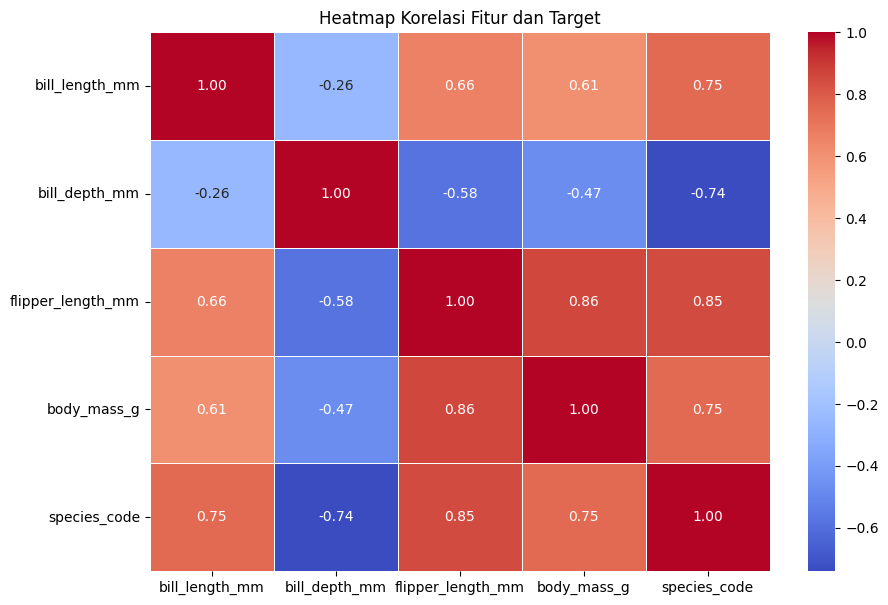

Korelasi Fitur terhadap Target:
flipper_length_mm    0.849596
body_mass_g          0.753798
bill_length_mm       0.750303
bill_depth_mm        0.740100
Name: species_code, dtype: float64

3 Fitur Terpilih:
['flipper_length_mm', 'body_mass_g', 'bill_length_mm']


In [8]:

# Mengubah target species menjadi kode angka
target_code = train_df['species'].astype('category').cat.codes

# Menggabungkan fitur numerik dengan target
df_corr = train_df.drop(columns=['species']).copy()
df_corr['species_code'] = target_code

# Menghitung korelasi
correlation = df_corr.corr()

# Membuat heatmap korelasi
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Heatmap Korelasi Fitur dan Target')
plt.show()

# Menghitung korelasi absolut terhadap target
target_corr = correlation['species_code'].drop(
    'species_code'
).abs().sort_values(ascending=False)

print("Korelasi Fitur terhadap Target:")
print(target_corr)

# Memilih 3 fitur dengan korelasi tertinggi
fitur_terpilih = target_corr.head(3).index.tolist()

print("\n3 Fitur Terpilih:")
print(fitur_terpilih)


**Jawaban 3.1:**

Berdasarkan hasil analisis korelasi, tiga fitur yang memiliki nilai korelasi absolut tertinggi terhadap target `species` adalah:

1. `flipper_length_mm`
2. `body_mass_g`
3. `bill_length_mm`

Ketiga fitur tersebut dipilih karena memiliki hubungan korelasi paling kuat terhadap target dibandingkan fitur lainnya. Oleh karena itu, ketiga fitur dianggap paling relevan untuk digunakan dalam proses klasifikasi spesies penguin.

**Soal 3.2** (4 poin)

**Univariat:** buat histogram (dengan KDE) untuk dua fitur numerik pilihan Anda (satu figure, dua subplot).

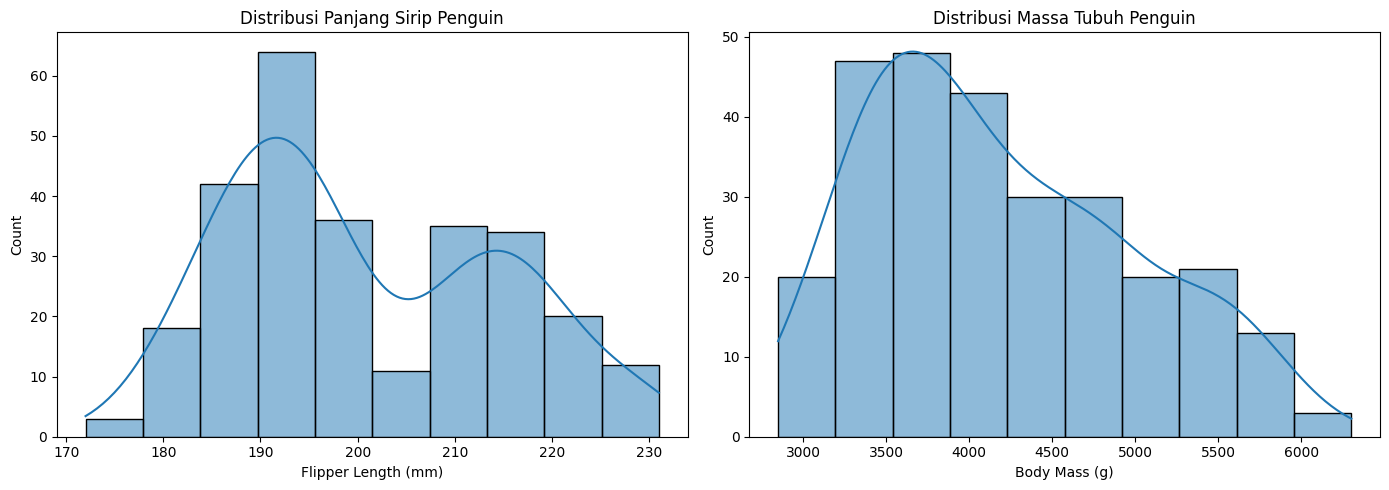

In [9]:

# Membuat histogram dengan KDE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=train_df,
    x='flipper_length_mm',
    kde=True,
    ax=axes[0]
)
axes[0].set_title('Distribusi Panjang Sirip Penguin')
axes[0].set_xlabel('Flipper Length (mm)')

sns.histplot(
    data=train_df,
    x='body_mass_g',
    kde=True,
    ax=axes[1]
)
axes[1].set_title('Distribusi Massa Tubuh Penguin')
axes[1].set_xlabel('Body Mass (g)')

plt.tight_layout()
plt.show()


**Soal 3.3** (5 poin)

**Bivariat:** buat *box plot* **dan** *violin plot* dua fitur numerik terhadap kelas target. Pada Markdown, tulis **satu temuan**.

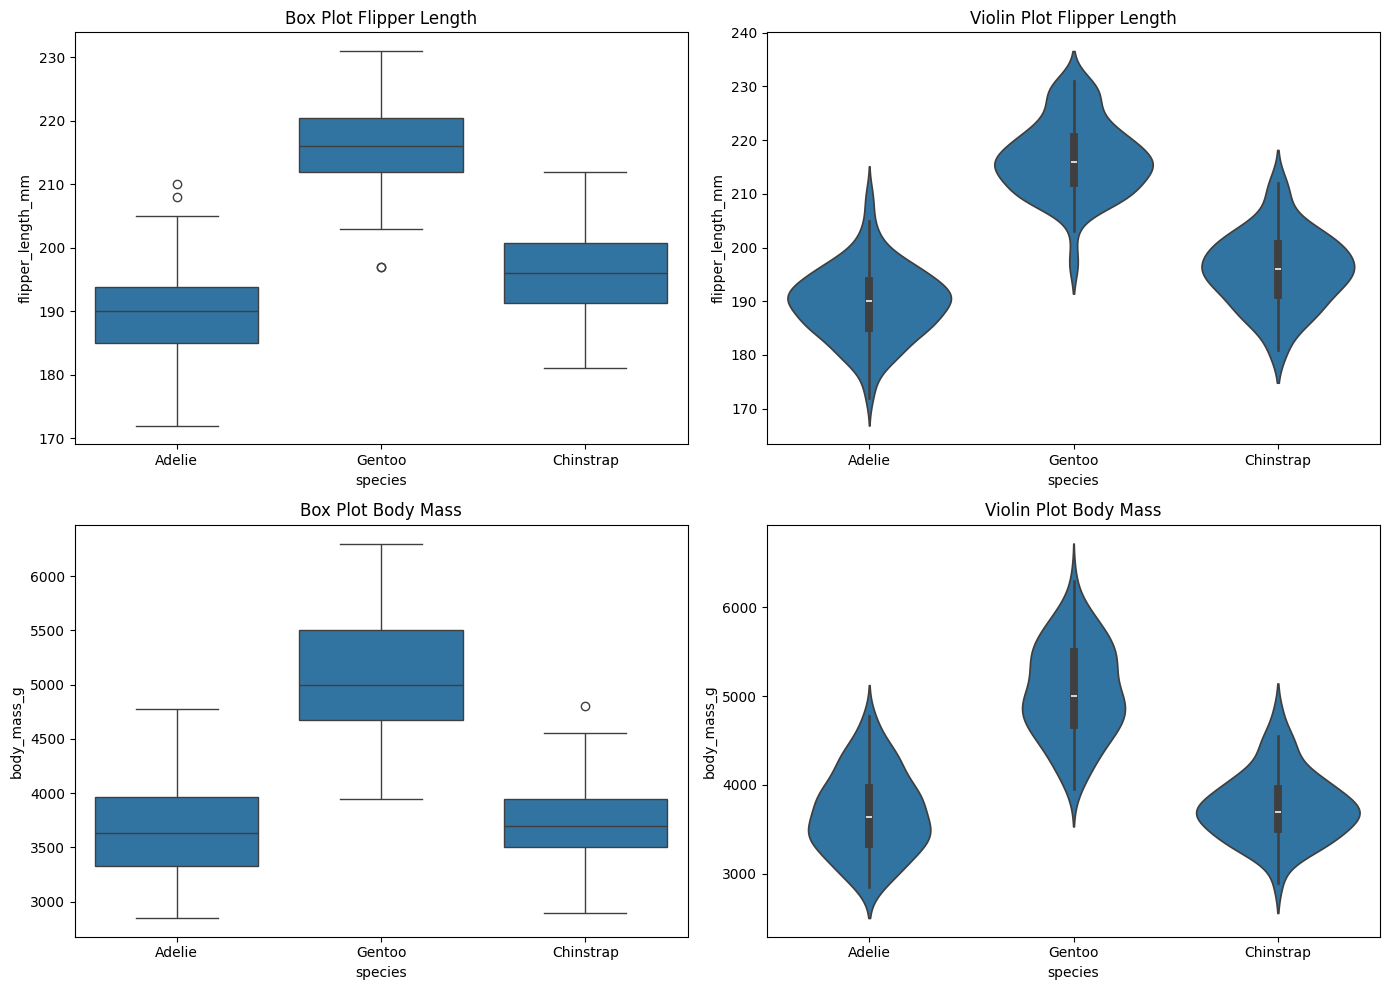

In [10]:

# Membuat box plot dan violin plot
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Box plot flipper length
sns.boxplot(
    data=train_df,
    x='species',
    y='flipper_length_mm',
    ax=axes[0, 0]
)
axes[0, 0].set_title('Box Plot Flipper Length')

# Violin plot flipper length
sns.violinplot(
    data=train_df,
    x='species',
    y='flipper_length_mm',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Violin Plot Flipper Length')

# Box plot body mass
sns.boxplot(
    data=train_df,
    x='species',
    y='body_mass_g',
    ax=axes[1, 0]
)
axes[1, 0].set_title('Box Plot Body Mass')

# Violin plot body mass
sns.violinplot(
    data=train_df,
    x='species',
    y='body_mass_g',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Violin Plot Body Mass')

plt.tight_layout()
plt.show()


**Jawaban 3.3:**

Berdasarkan hasil box plot dan violin plot, terdapat perbedaan distribusi panjang sirip dan massa tubuh pada setiap spesies penguin. Spesies Gentoo cenderung memiliki panjang sirip dan massa tubuh lebih besar dibandingkan Adelie dan Chinstrap. Hal ini menunjukkan bahwa kedua fitur tersebut dapat membantu membedakan spesies penguin dalam proses klasifikasi.

## Fase 4 - Supervised Modelling (Klasifikasi: SVM vs Random Forest) (25 poin)

**Soal 4.1** (10 poin)

Buat `X_train, X_test, y_train, y_test` memakai `fitur_terpilih` (target `species`). Latih **SVM** `SVC(kernel="linear")` di dalam `Pipeline` bersama `StandardScaler` (lihat Modul 6, Langkah 11).

In [ ]:
# Tulis jawaban Anda di sini

**Soal 4.2** (10 poin)

Latih **Random Forest** `RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)` pada data yang sama (lihat Modul 7, Langkah 5).

In [ ]:
# Tulis jawaban Anda di sini

**Soal 4.3** (5 poin)

Jawab pada Markdown: (a) mengapa SVM memerlukan *scaling* sedangkan Random Forest tidak? (b) mengapa `StandardScaler` tidak boleh di-`fit` pada seluruh data sebelum split, dan bagaimana `Pipeline` mencegahnya?

**Jawaban 4.3:**

(tulis jawaban Anda di sini)

## Fase 5 - Evaluation & Contrast (25 poin)
> Semua evaluasi dilakukan pada **data test**.

**Soal 5.1** (14 poin)

Untuk **kedua model**, tampilkan *confusion matrix* (sebagai plot) dan `classification_report` (lihat Modul 6, Langkah 10 dan Modul 7, Langkah 6).

In [ ]:
# Tulis jawaban Anda di sini

**Soal 5.2** (11 poin)

**Contrast** (Markdown): (a) model mana yang lebih baik? rujuk accuracy / F1. (b) kelas mana yang paling sering salah diprediksi? (c) berikan satu kemungkinan alasan perbedaan performa kedua model.

**Jawaban 5.2:**

(tulis jawaban Anda di sini)

## Fase 6 - Feature Importance (10 poin)

**Soal 6.1** (7 poin)

Ekstrak `feature_importances_` dari Random Forest ke dalam DataFrame (kolom `Feature` dan `Importance`) yang terurut menurun, tampilkan, lalu buat *barplot* dengan seaborn (lihat Modul 7, Langkah 7-8).

In [ ]:
# Tulis jawaban Anda di sini

**Soal 6.2** (3 poin)

Markdown: sebutkan 3 fitur paling berpengaruh dan beri satu kalimat interpretasi.

**Jawaban 6.2:**

(tulis jawaban Anda di sini)